# Sesión 9 · Clustering: K-means y Clustering Jerárquico

> **Minería de Datos · UNIMINUTO Ibagué · 2026-2**  
> Docente: Esteban Ernesto Morales Castro  
> Proyecto: **AUTOGEST** — Análisis de Siniestralidad Vial en Ibagué

---

## Objetivos de la sesión
1. **Diferenciar** aprendizaje supervisado y no supervisado.
2. **Trazar** K-means paso a paso y elegir k con método del codo + coeficiente de silueta.
3. **Ejecutar** una segmentación completa con `KMeans + StandardScaler` y perfilar con `groupby().mean()`.
4. **Nombrar** comercialmente cada clúster y leer un dendrograma jerárquico.

---

> **Recordatorio crítico:**  
> ✅ Siempre `StandardScaler` **antes** de `KMeans` — misma regla que con KNN.  
> ✅ La variable objetivo (`ACCIDENTES_REGISTRADOS`) **NO** entra en X — se usa solo para perfilar.  
> ✅ Los centroides en `km.cluster_centers_` están en escala estandarizada — para narrar, usa las medias reales del `groupby`.

## 0 · Configuración del entorno

In [1]:
import sys
from pathlib import Path

raiz = Path.cwd().parent if Path.cwd().name == "analisis" else Path.cwd()
if str(raiz) not in sys.path:
    sys.path.insert(0, str(raiz))

print("Raíz del proyecto:", raiz)

import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.float_format", "{:.2f}".format)
pd.set_option("display.max_columns", 20)
print("Entorno listo ✓")

Raíz del proyecto: c:\Users\Gilary Gacha\Desktop\autogest
Entorno listo ✓


## 1 · Carga del módulo Clustering

In [2]:
from src.clustering import Clustering

cl = Clustering(ruta="dataset/dataset_integrado.csv")
df = cl.cargar()

print(f"Dataset AUTOGEST cargado: {df.shape[0]:,} filas × {df.shape[1]} columnas")
print(f"\nVariables de clustering ({len(cl._vars)}):")
for v in cl._vars:
    print(f"  · {v}")
print(f"\nVariable objetivo (solo para perfilar): {cl.OBJETIVO}")
df[cl._vars + [cl.OBJETIVO]].describe().T.round(2)

Dataset AUTOGEST cargado: 507 filas × 18 columnas

Variables de clustering (6):
  · VOLUMEN_TRAFICO
  · VEHICULOS_EVASORES
  · VEHICULOS_EXENTOS
  · SERVICIOS_TALLER
  · COSTO_TOTAL_TALLER
  · MILLAJE_PROMEDIO

Variable objetivo (solo para perfilar): ACCIDENTES_REGISTRADOS


,count,mean,std,min,25%,50%,75%,max
VOLUMEN_TRAFICO,507.00,6475939.78,5897085.89,0.00,3121770.00,3574005.00,12020490.00,22371088.00
VEHICULOS_EVASORES,507.00,1155.87,13691.79,0.00,0.00,2.00,21.50,273077.00
VEHICULOS_EXENTOS,507.00,52971.06,65961.61,0.00,9941.00,14457.00,139561.00,237927.00
SERVICIOS_TALLER,507.00,3944.77,4587.10,0.00,0.00,0.00,5741.00,11516.00
COSTO_TOTAL_TALLER,507.00,1476214.65,1717313.56,0.00,0.00,0.00,2159990.52,4367279.09
MILLAJE_PROMEDIO,507.00,73356.10,77451.78,0.00,0.00,0.00,154889.66,157924.86
ACCIDENTES_REGISTRADOS,507.00,746.02,899.26,0.00,207.50,400.00,1015.00,4458.00


## 2 · Escalado de las variables (obligatorio antes de KMeans)

> **¿Por qué escalar?**  
> Sin `StandardScaler`, `COSTO_TOTAL_TALLER` (millones de pesos) dominaría la distancia euclidiana  
> y `MES` o `MILLAJE_PROMEDIO` quedarían invisibles para el algoritmo.  
> Misma lección que KNN (Sesión 8): **"distancia manda a escalar"**.

In [3]:
X_scaled = cl.preparar_x()

print(f"Forma de X escalada: {X_scaled.shape}")
print(f"Media por columna (≈ 0): {X_scaled.mean(axis=0).round(4)}")
print(f"Desv. estándar (≈ 1):   {X_scaled.std(axis=0).round(4)}")

Forma de X escalada: (507, 6)
Media por columna (≈ 0): [-0.  0. -0. -0. -0.  0.]
Desv. estándar (≈ 1):   [1. 1. 1. 1. 1. 1.]


## 3 · Búsqueda del k óptimo (Código 1 de la demo)

Calculamos **inercia** (método del codo) y **coeficiente de silueta** para k = 2 … 8.

| Métrica | Lógica | Mejor cuando |
|---|---|---|
| **Inercia** | Suma de distancias² al centroide | Busca el "codo" donde la bajada se vuelve suave |
| **Silueta** | (separación - cohesión) / max | El valor más alto indica mejor estructura |

In [4]:
# Código 1 de la demo guiada (diapositiva 11)
tabla_k = cl.buscar_k(k_min=2, k_max=8, verbose=True)
tabla_k


──────────────────────────────────────────────────────────────
         BÚSQUEDA DEL K ÓPTIMO · AUTOGEST · Sesión 9          
──────────────────────────────────────────────────────────────
   k       inercia   silueta  Lectura
──────────────────────────────────────────────────────────────
   2        1682.0     0.560  Referencia mínima de k
   3        1165.3     0.633  
   4         691.9     0.766  
   5         300.8     0.772  
   6         174.9     0.825  
   7         103.4     0.829  ← MÁXIMA silueta
   8          87.8     0.808  
──────────────────────────────────────────────────────────────



,k,inercia,silueta,Lectura
0,2,1682.00,0.56,Referencia mínima de k
1,3,1165.30,0.63,
2,4,691.90,0.77,
3,5,300.80,0.77,
4,6,174.90,0.83,
5,7,103.40,0.83,← MÁXIMA silueta
6,8,87.80,0.81,


### Interpretación
Observe dónde la inercia deja de caer bruscamente (codo) y cuál k maximiza la silueta.
El k elegido debe satisfacer **ambos criterios** y tener sentido operacional:  
"¿Podemos operar X campañas distintas?"

## 4 · Modelo K-means final (Código 2 de la demo, parte 1)

> Ajuste con el k elegido. Modifique `K_ELEGIDO` si su análisis del codo/silueta sugiere otro valor.

In [5]:
# ── DECISIÓN DE k ────────────────────────────────────────────────────────────
# Justifique aquí con cifras de la tabla anterior:
# "El codo dobla entre k=__ y k=__; la silueta máxima está en k=__.
#  Elegimos k=__ por viabilidad operacional (__ campañas diferenciadas)."
K_ELEGIDO = 3   # ← modifique según su análisis

cl.ajustar(k=K_ELEGIDO)


── KMeans ajustado con k=3 ──────────────────────────
  Clúster 0:   267 observaciones (52.7%)
  Clúster 1:   182 observaciones (35.9%)
  Clúster 2:    58 observaciones (11.4%)
  Inercia total: 1165.3
  Silueta global: 0.6331
────────────────────────────────────────────────────────


## 5 · Perfilamiento con groupby (Código 2 de la demo, parte 2)

Medias **reales** (escala original) por clúster — **NO** los centroides estandarizados.

In [6]:
perfil = cl.perfilar(incluir_objetivo=True)
print("\nPerfiles por clúster (medias en escala original):")
display(perfil)


Perfiles por clúster (medias en escala original):


,n_obs,pct_obs,VOLUMEN_TRAFICO,VEHICULOS_EVASORES,VEHICULOS_EXENTOS,SERVICIOS_TALLER,COSTO_TOTAL_TALLER,MILLAJE_PROMEDIO,ACCIDENTES_REGISTRADOS
cluster,,,,,,,,,
0,267,52.70,7220301.59,873.21,60920.54,0.00,0.00,0.00,1088.80
1,182,35.90,2372814.66,373.23,8276.79,7448.59,2786870.36,155009.65,155.18
2,58,11.40,15924632.33,4912.93,156623.60,11109.60,4159145.19,154823.88,1022.10


## 6 · Nomenclatura comercial de los segmentos (Paso 4 del taller)

Un segmento sin nombre no existe para operaciones.  
El entregable NO es el número de grupo: es el **nombre**, el **retrato robot** y la **campaña**.

In [7]:
# ── Revise el perfil anterior y asigne nombres según el comportamiento ────────
# Ejemplo para datos AUTOGEST (ajuste según sus resultados):
nombres_seg = {
    0: "Período de tráfico habitual",
    1: "Período de alta siniestralidad",
    2: "Período de baja actividad",
}
campanas_seg = {
    0: "Mantenimiento preventivo estándar · monitoreo trimestral",
    1: "Alerta temprana · inspección inmediata · refuerzo de señalización",
    2: "Revisión de subutilización · análisis de causas de baja demanda",
}

df_nombres = cl.nombrar_segmentos(nombres=nombres_seg, campanas=campanas_seg)
display(df_nombres)


── Segmentos nombrados ─────────────────────────────────
  [0] Período de tráfico habitual · 267 obs (52.7%)
       Campaña: Mantenimiento preventivo estándar · monitoreo trimestral
  [1] Período de alta siniestralidad · 182 obs (35.9%)
       Campaña: Alerta temprana · inspección inmediata · refuerzo de señalización
  [2] Período de baja actividad · 58 obs (11.4%)
       Campaña: Revisión de subutilización · análisis de causas de baja demanda
────────────────────────────────────────────────────────


,cluster,nombre,n_obs,pct_obs,campaña
0,0,Período de tráfico habitual,267,52.70,Mantenimiento preventivo estándar · monitoreo ...
1,1,Período de alta siniestralidad,182,35.90,Alerta temprana · inspección inmediata · refue...
2,2,Período de baja actividad,58,11.40,Revisión de subutilización · análisis de causa...


## 7 · Pista técnica: variar k y ver efecto en silueta

Reproducción del snippet de la diapositiva 20 de la presentación.

In [8]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

print(f"{'k':>4}  {'inercia':>12}  {'silueta':>8}")
print("-" * 30)
for k in [2, 3, 4, 5, 6]:
    km_tmp = KMeans(n_clusters=k, n_init=10, random_state=42)
    etiquetas = km_tmp.fit_predict(cl.X_scaled)
    sil = silhouette_score(cl.X_scaled, etiquetas)
    print(f"{k:>4}  {km_tmp.inertia_:>12.0f}  {sil:>8.3f}")

   k       inercia   silueta
------------------------------
   2          1682     0.560
   3          1165     0.633
   4           692     0.766
   5           301     0.772
   6           175     0.825


## 8 · Clustering Jerárquico y Dendrograma (Código 3 de la demo)

Se aplica sobre una **muestra de 60 filas** (práctica estándar por la complejidad O(n²)).  
El dendrograma confirma (o cuestiona) el k elegido con K-means.


── Dendrograma jerárquico (ward) · muestra n=60 ──
  Primeras 5 fusiones (distancia): [0.01, 0.01, 0.01, 0.01, 0.01]
  Última fusión (distancia total): 17.50
  Una línea horizontal a ~7.5 cruzaría 3 ramas → coherente con k=3
────────────────────────────────────────────────────────
[OK] fig_dendrograma_jerarquico.png


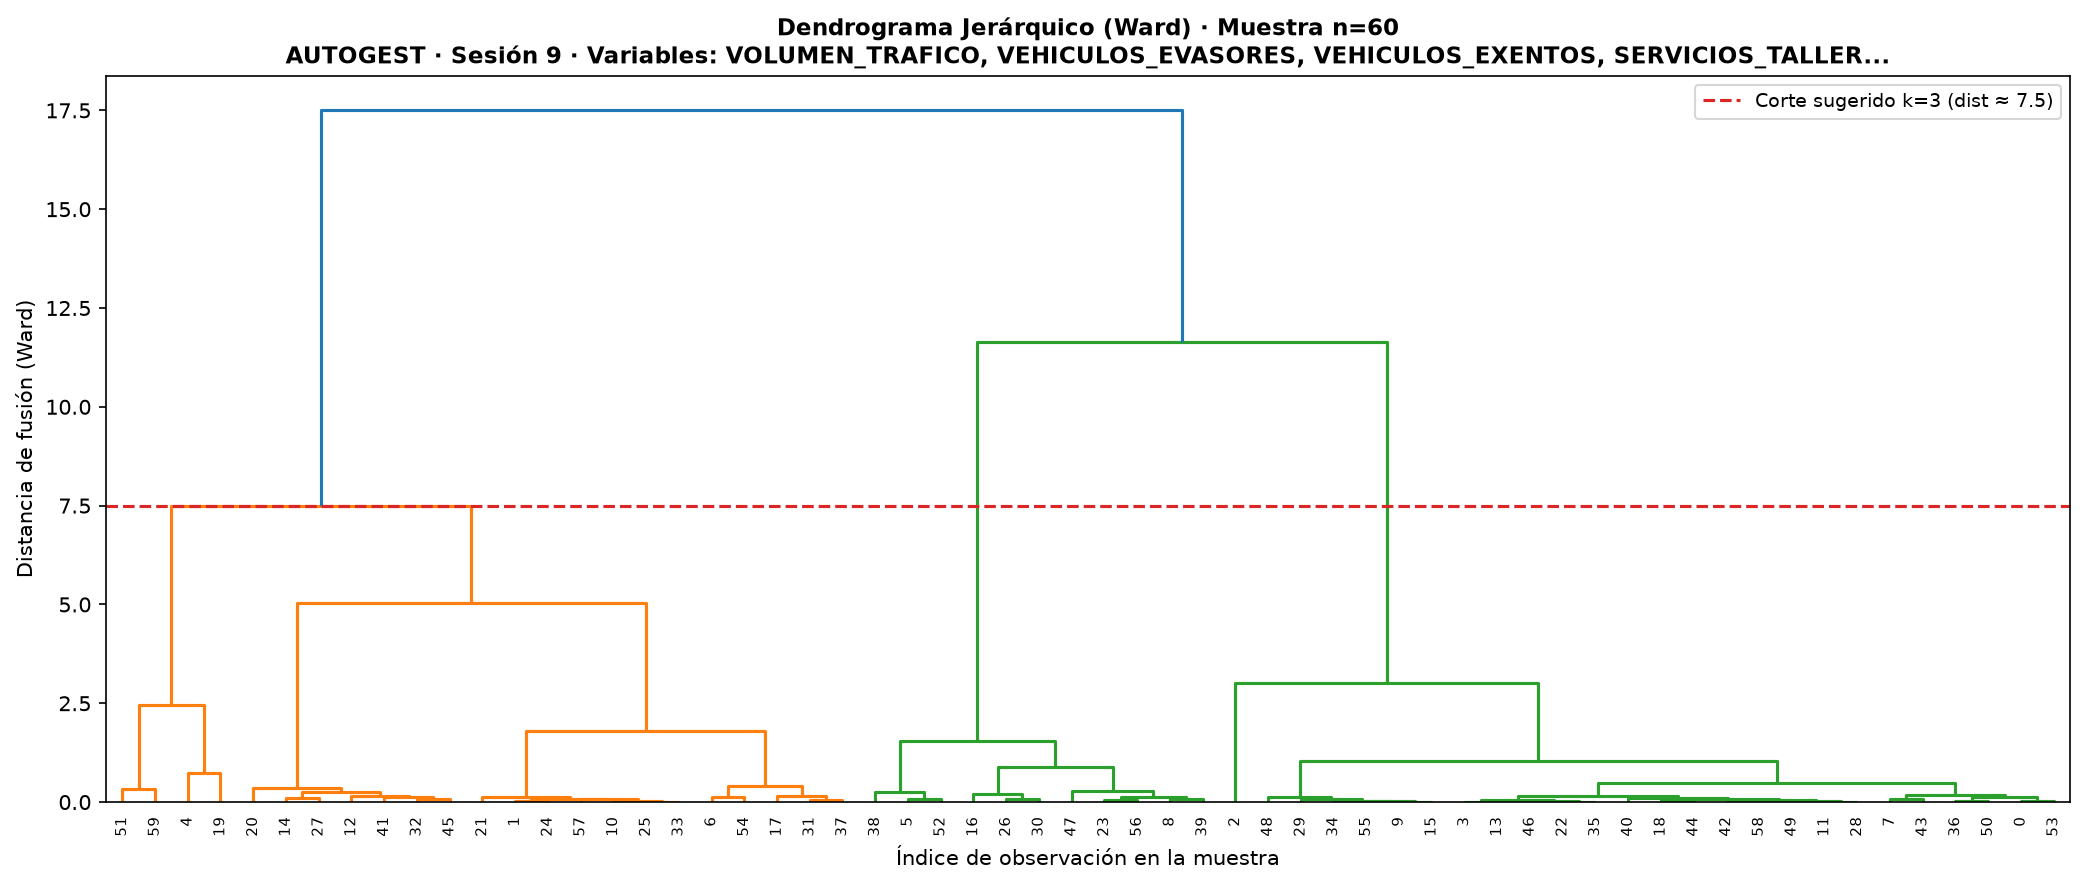

In [9]:
ruta_dend = cl.dendrograma(
    n_muestra=60,
    random_state=42,
    carpeta_salida="analisis/figuras",
    verbose=True,
)

from IPython.display import Image
Image(filename=ruta_dend, width=820)

### Lectura del dendrograma
- **Fusiones bajas** (eje Y pequeño): pares de períodos casi idénticos en comportamiento.
- **Última fusión alta**: los dos macro-grupos finales están bien separados.
- **Línea roja horizontal** = corte sugerido para k={K_ELEGIDO}.
- Cuente cuántas ramas cruza la línea → debe confirmar su k.

## 9 · Generación de figuras diagnósticas

[OK] fig_clustering_codo_silueta.png
[OK] fig_clustering_scatter_pca.png
[OK] fig_clustering_perfiles.png
[OK] fig_clustering_barras_perfil.png
[OK] fig_dendrograma_jerarquico.png

[OK] Todas las figuras de la Sesión 9 guardadas en: C:\Users\Gilary Gacha\Desktop\autogest\analisis\figuras

── fig_codo_silueta ──


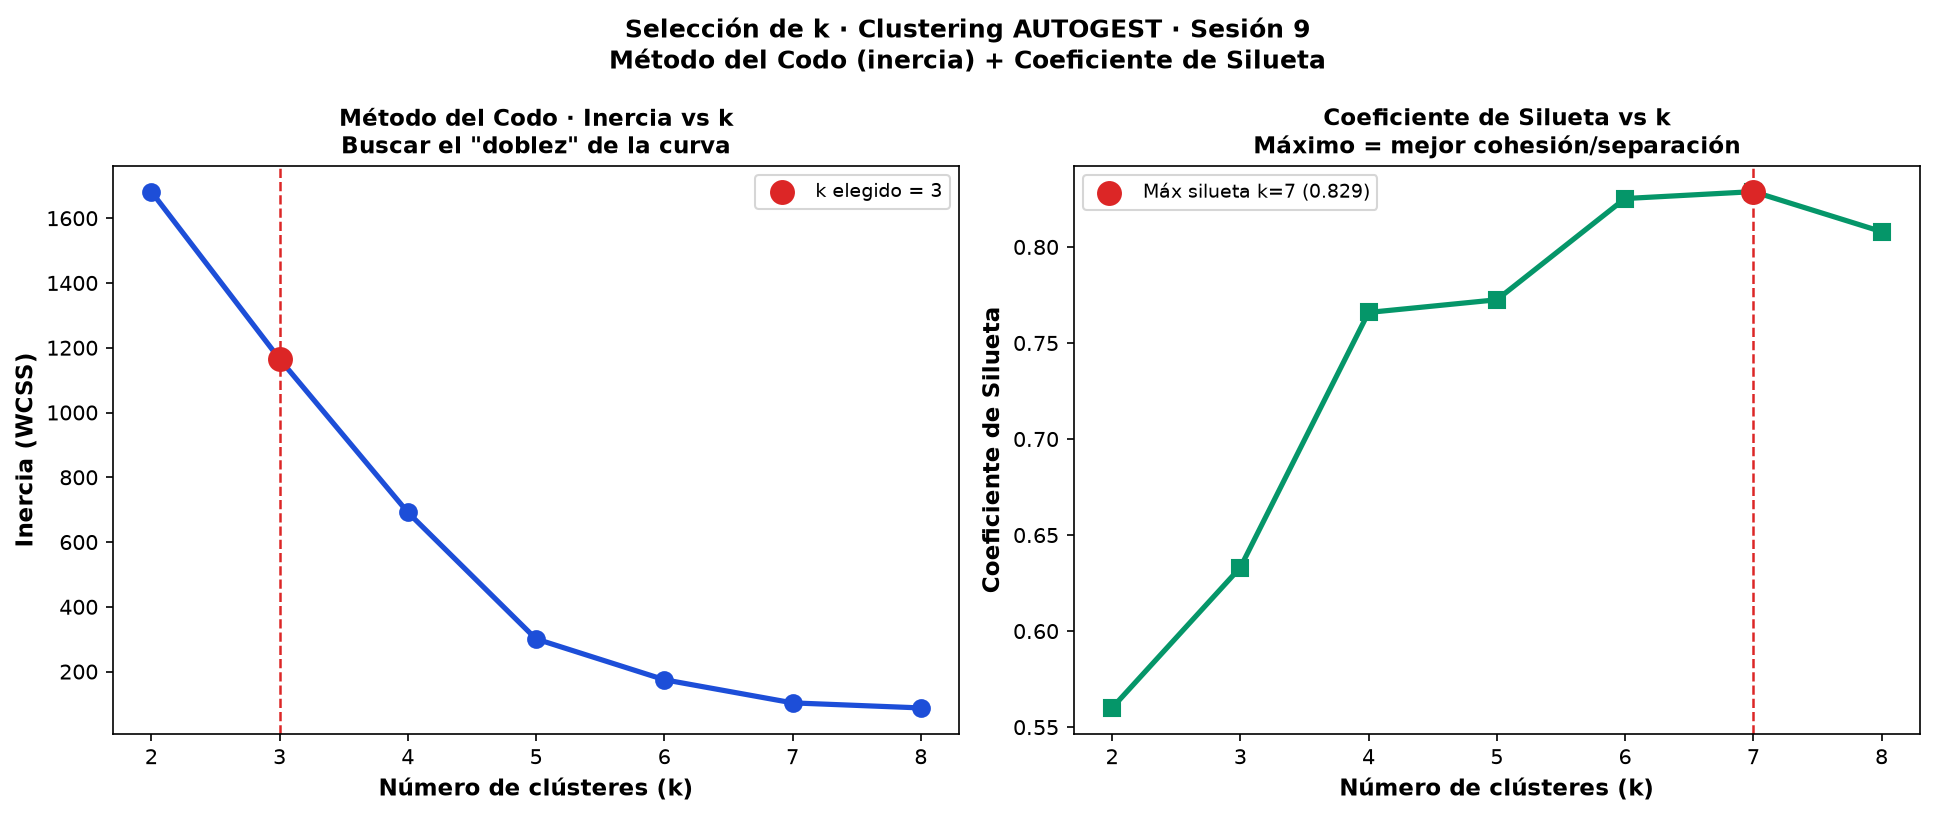


── fig_scatter_pca ──


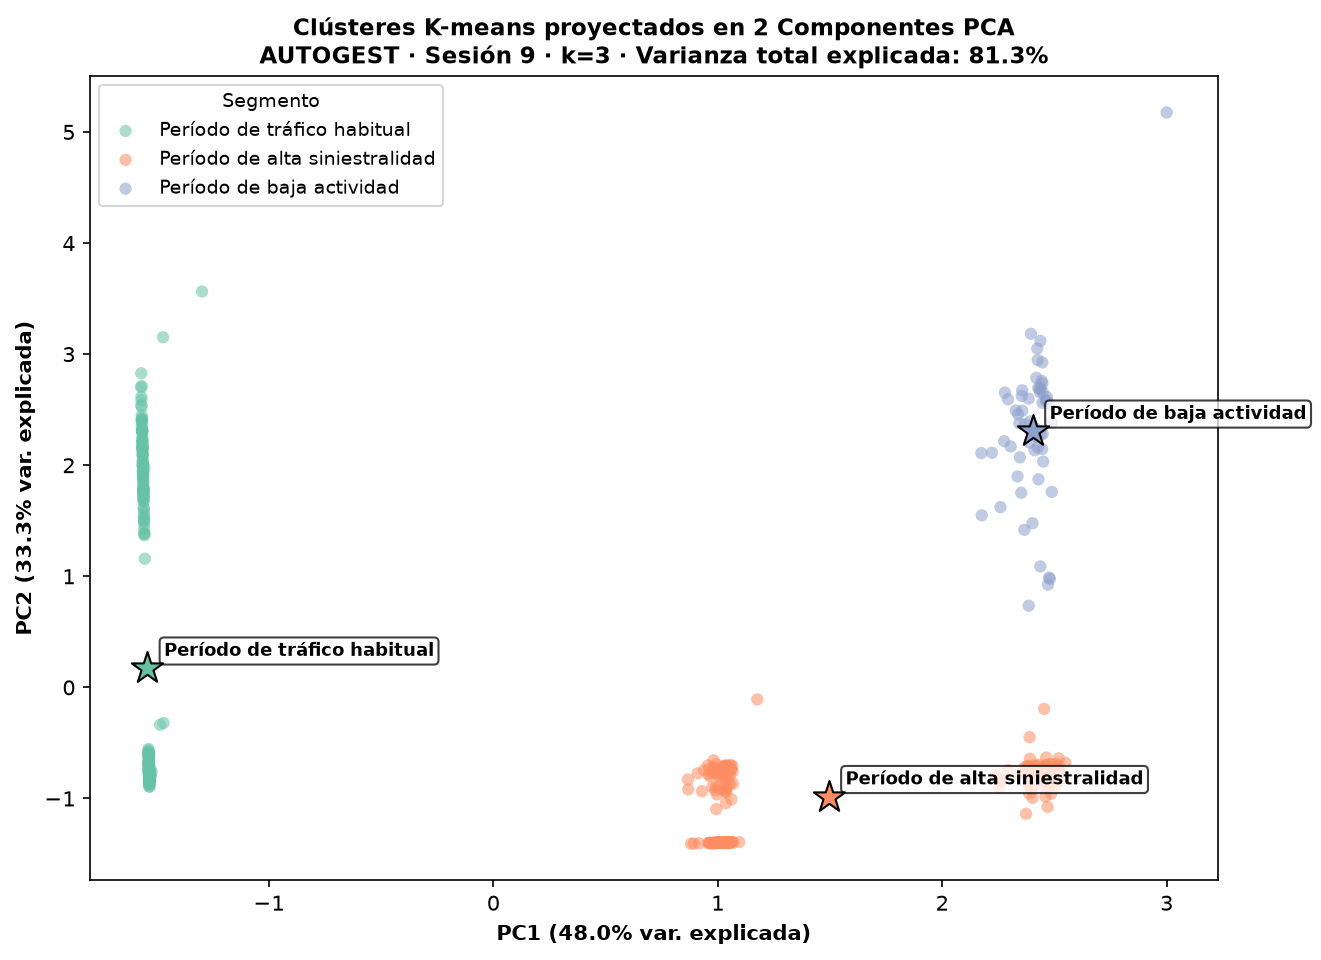


── fig_perfiles ──


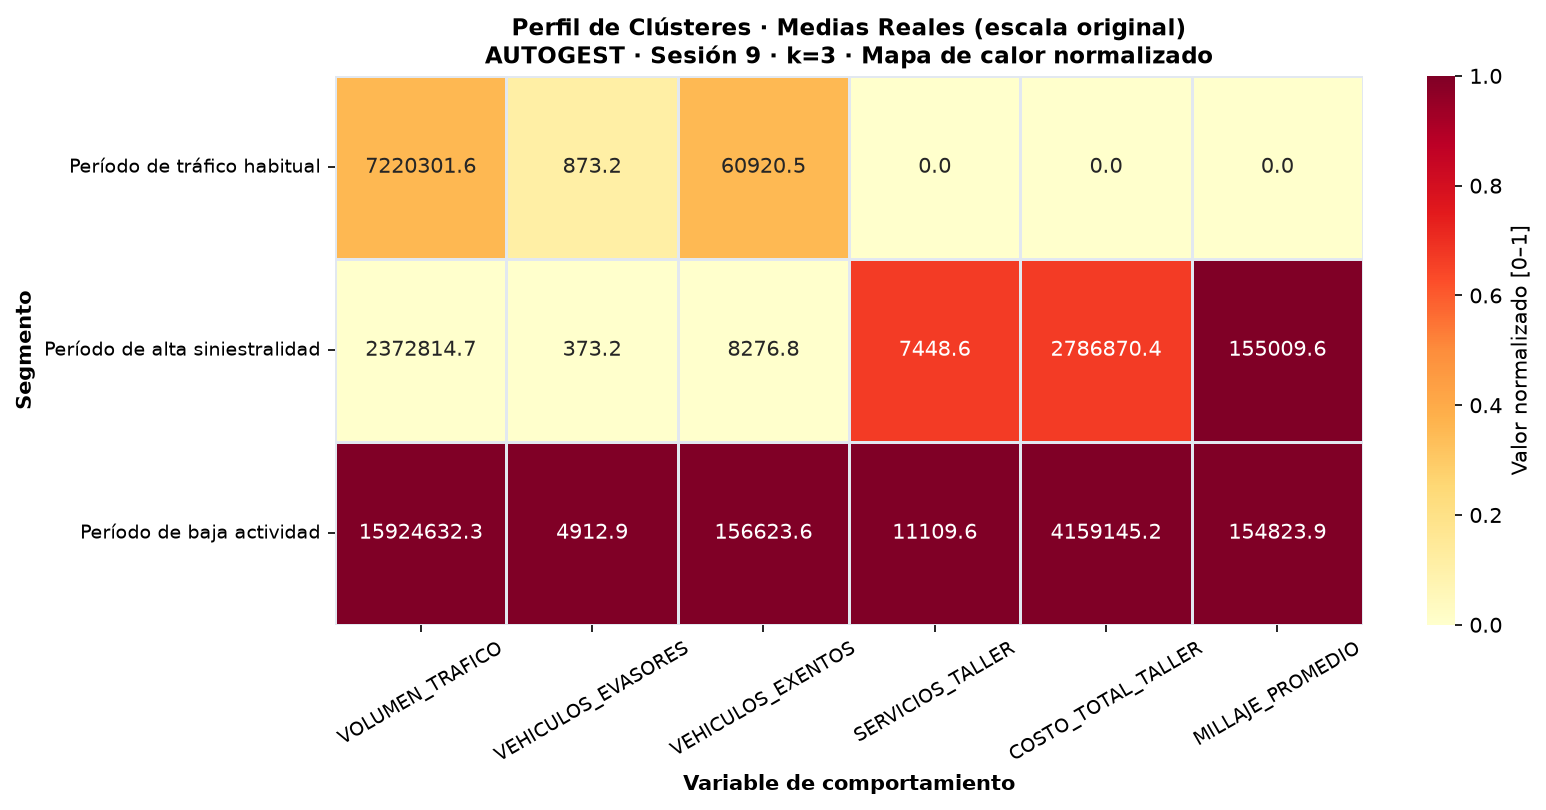


── fig_barras_perfil ──


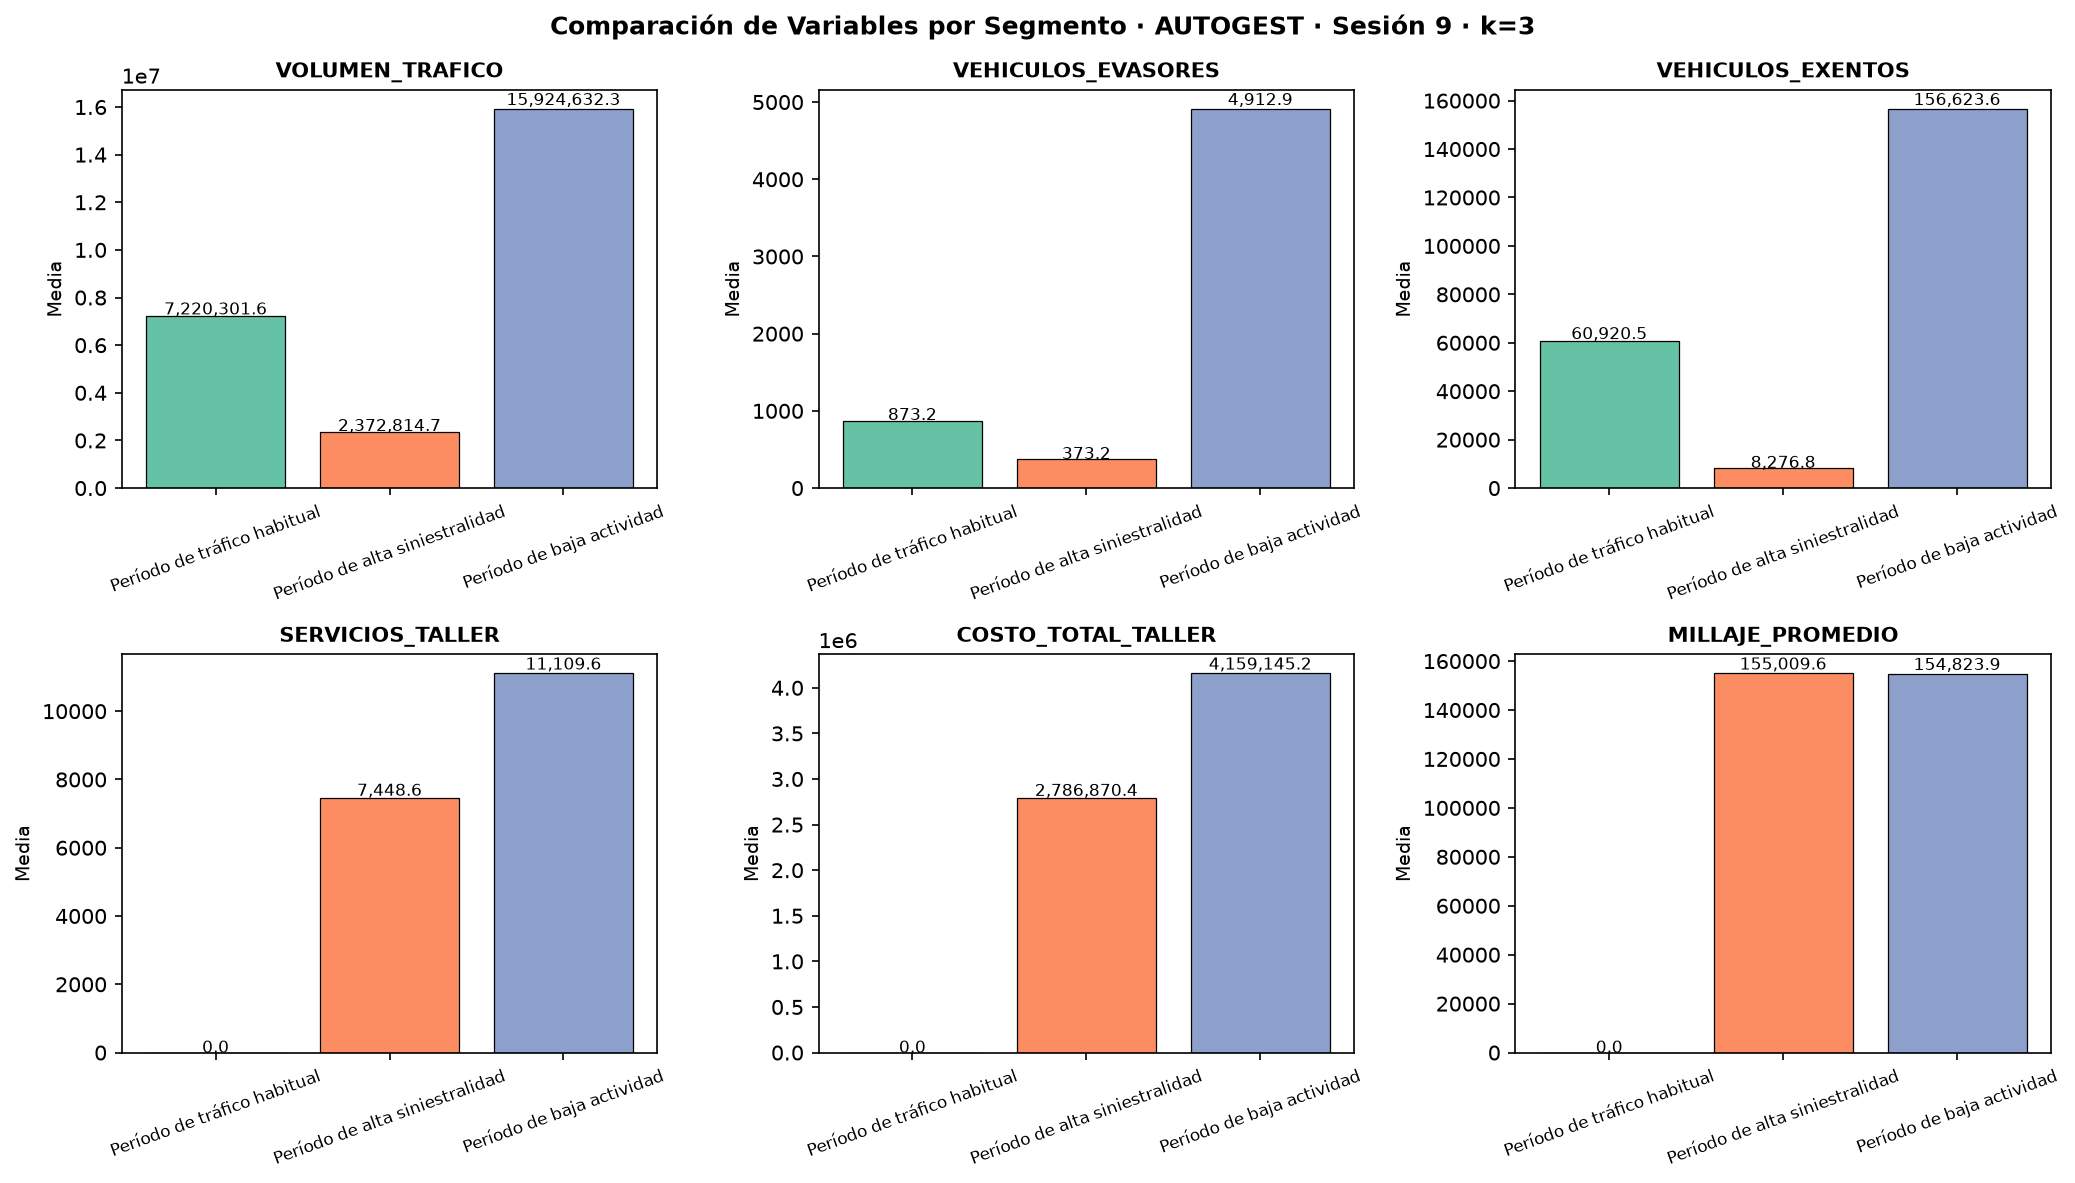


── fig_dendrograma ──


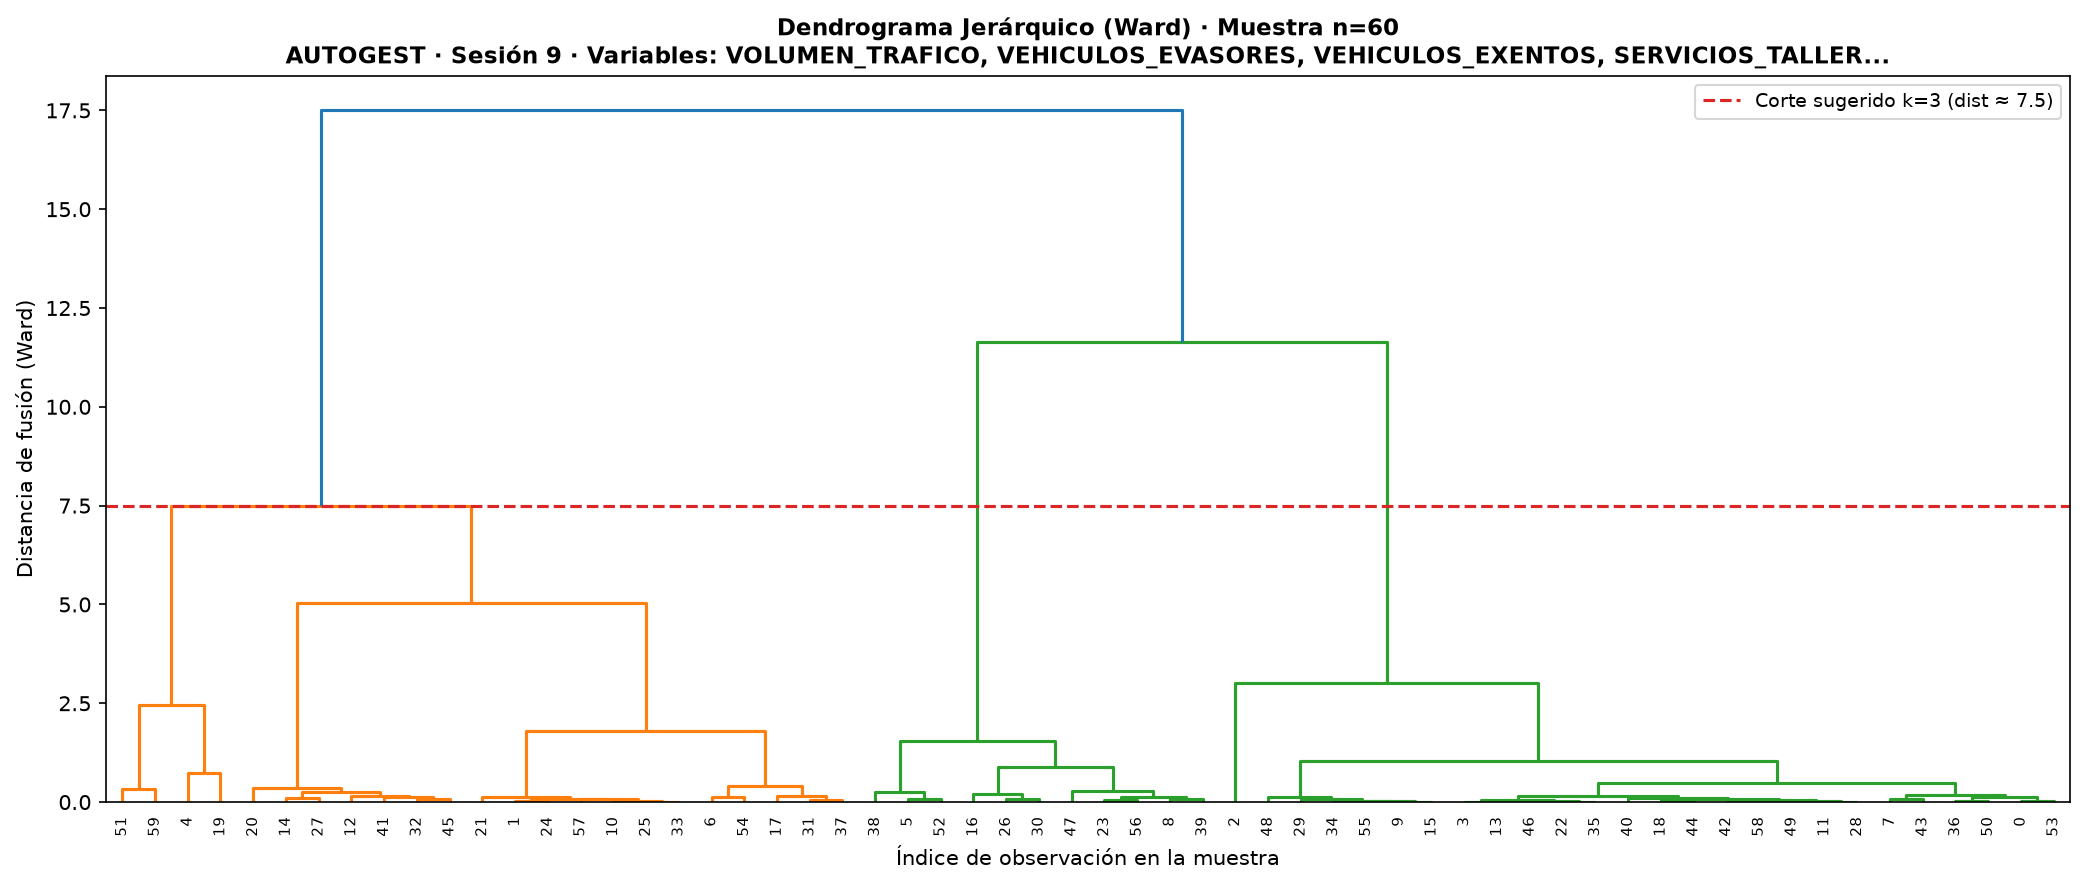

In [10]:
rutas = cl.generar_figuras(carpeta_salida="analisis/figuras")

from IPython.display import Image, display as ipy_display
for nombre_fig, ruta_fig in rutas.items():
    print(f"\n── {nombre_fig} ──")
    ipy_display(Image(filename=ruta_fig, width=820))

## 10 · Resumen ejecutivo (Avance 2)

Texto estructurado listo para incluir en el documento del Avance 2.

In [11]:
resumen = cl.resumen_avance2()

═════════════════════════════════════════════════════════════════
RESUMEN DE SEGMENTACIÓN · AUTOGEST · Sesión 9
Minería de Datos · UNIMINUTO Ibagué · 2026-2
═════════════════════════════════════════════════════════════════

k elegido: 3 clústeres
Variables de clustering (6): VOLUMEN_TRAFICO, VEHICULOS_EVASORES, VEHICULOS_EXENTOS, SERVICIOS_TALLER, COSTO_TOTAL_TALLER, MILLAJE_PROMEDIO
Método: KMeans (n_init=10, random_state=42) + StandardScaler
Silueta global: 0.6331

Tamaño de la base: 507 observaciones

PERFILES POR SEGMENTO (medias en escala original):
─────────────────────────────────────────────────────────────────
         n_obs  pct_obs  VOLUMEN_TRAFICO  VEHICULOS_EVASORES  VEHICULOS_EXENTOS  SERVICIOS_TALLER  COSTO_TOTAL_TALLER  MILLAJE_PROMEDIO  ACCIDENTES_REGISTRADOS
cluster                                                                                                                                                        
0          267    52.70       7220301.59             

## 11 · Integrar el clúster como feature supervisado

> **Idea poderosa del Avance 2:** el segmento descubierto hoy puede convertirse  
> mañana en una variable predictora del modelo supervisado (Sesión 8).  
> El clustering enriquece X para los modelos de clasificación.

In [12]:
# Verificar que la columna 'segmento' quedó en el DataFrame
print("Distribución de segmentos:")
display(cl.df["segmento"].value_counts())

print("\nTasa de siniestralidad promedio por segmento:")
if cl.OBJETIVO in cl.df.columns:
    display(
        cl.df.groupby("segmento")[cl.OBJETIVO]
        .mean().round(2)
        .rename("Media ACCIDENTES_REGISTRADOS")
    )

print("\nPrimeras filas con la nueva columna 'segmento':")
cl.df[["cluster", "segmento"] + cl._vars[:3]].head(8)

Distribución de segmentos:


segmento
Período de tráfico habitual       267
Período de alta siniestralidad    182
Período de baja actividad          58
Name: count, dtype: int64


Tasa de siniestralidad promedio por segmento:


segmento
Período de alta siniestralidad    155.18
Período de baja actividad        1022.10
Período de tráfico habitual      1088.80
Name: Media ACCIDENTES_REGISTRADOS, dtype: float64


Primeras filas con la nueva columna 'segmento':


,cluster,segmento,VOLUMEN_TRAFICO,VEHICULOS_EVASORES,VEHICULOS_EXENTOS
0,0,Período de tráfico habitual,3135469.00,2.00,10689.00
1,0,Período de tráfico habitual,13980059.00,30.00,132797.00
2,0,Período de tráfico habitual,3078197.00,0.00,17881.00
3,0,Período de tráfico habitual,3056757.00,3.00,10041.00
4,0,Período de tráfico habitual,9644989.00,25.00,128220.00
5,0,Período de tráfico habitual,2738503.00,2.00,17779.00
6,0,Período de tráfico habitual,3280363.00,2.00,10288.00
7,0,Período de tráfico habitual,10974101.00,29.00,143208.00


---

## Checklist del ejercicio en clase

| # | Requisito | ¿Cumplido? |
|---|---|---|
| 1 | Escalar variables ANTES de KMeans (StandardScaler) | ✅ Sección 2 |
| 2 | Tabla inercia + silueta para k=2..6 | ✅ Sección 3 |
| 3 | Decisión de k justificada (codo + silueta + viabilidad) | ✅ Sección 4 |
| 4 | Perfiles con groupby().mean() en escala REAL | ✅ Sección 5 |
| 5 | Tasa de ACCIDENTES por clúster incluida en perfil | ✅ Sección 5 |
| 6 | Nombres comerciales accionables + acción por segmento | ✅ Sección 6 |
| 7 | Dendrograma de muestra contrastado con k elegido | ✅ Sección 8 |
| 8 | Figuras exportadas a 150 DPI | ✅ Sección 9 |

---

**Anticipo Sesión 10 — Reglas de Asociación:**  
"Quien compra A lleva B": algoritmo Apriori sobre canastas de supermercado.  
Entrada con quiz corto.

---
*AUTOGEST · Ingeniería de Sistemas · UNIMINUTO Ibagué · 2026-2*